# Vertical integration: RNA + ADT

Vertical integration combines modalities measured in the same cells. This tutorial is for RNA and surface protein, as in CITE-seq. It runs Matilda and sciPENN on `D11`, a CITE-seq dataset of 2,864 cells, and then on data in your own format.

Methods run on Linux. On macOS or Windows, [open this notebook in Colab](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_vertical_rna_adt.ipynb).

## 1. Install

This cell installs `multibench-sc`. It keeps the numpy and pandas that are already installed, so Colab needs no restart.

<details>
<summary>Details</summary>

On Colab, choose a GPU runtime before you run the notebook: Runtime -> Change runtime type -> T4 GPU. On a CPU runtime, an environment that has a smaller CPU build gets that build, and training methods run slower.

</details>

In [1]:
import numpy, pandas
pins = f"numpy=={numpy.__version__} pandas=={pandas.__version__}"
%pip install -q "multibench-sc>=0.3.6" {pins}

Note: you may need to restart the kernel to use updated packages.


## 2. Download the data and the environments

`mtb.data.fetch` downloads `D11` (11 MB) once. Each method runs in its own environment. `mtb.env.install` downloads the environments for Matilda and sciPENN, with no conda needed. The download is 1.1 GB on a computer without a GPU and 5.1 GB on one with a GPU.

<details>
<summary>Details</summary>

`state` is `PACKED` for an environment downloaded now and `have` for one that was already there. Without `dry_run=False`, `mtb.env.install` downloads nothing and returns the plan with its sizes.

Environments go to `mtb.config.DEFAULT.envs_dir`. To use another disk, set it before this cell.

From a terminal, `multibench env install --methods Matilda,sciPENN --packed --run` does the same.

</details>

In [2]:
import pandas as pd
import multibench as mtb

mtb.data.fetch("D11")

downloading D11 (11 MB) from https://github.com/DSichang/scMultiBench/releases/download/data-v1/D11.tar.gz ...


PosixPath('/tmp/mbtut13/home/.cache/multibench/data')

In [3]:
METHODS = ["Matilda", "sciPENN"]
envs = mtb.env.install(METHODS, dry_run=False)
pd.DataFrame(envs)[["env", "methods", "state"]]

[env] downloading env_sciPENN (gpu build) 2.1 GB ...


[env]   0.2 GB of 2.1 GB (86 MB/s)


[env]   0.4 GB of 2.1 GB (94 MB/s)


[env]   0.6 GB of 2.1 GB (98 MB/s)


[env]   0.8 GB of 2.1 GB (101 MB/s)


...

[env]   2.4 GB of 3.0 GB (98 MB/s)


[env]   2.7 GB of 3.0 GB (97 MB/s)


[env]   3.0 GB of 3.0 GB (96 MB/s)


[env] unpacking matilda -> /tmp/mbtut13/home/.cache/multibench/envs/matilda ...


,env,methods,state
0,env_sciPENN,[sciPENN],PACKED
1,matilda,[Matilda],PACKED


## 3. Run the methods

`run_all` runs each method on `D11` and scores its output with the scIB metrics. `res.summary` has one row per method with its status, run time and scores. Higher is better for every metric.

<details>
<summary>Details</summary>

Each method writes an embedding: a table of numbers with one row per cell. `run_all` scores it against the cell-type labels of `D11`.

The clustering metrics `ARI`, `NMI`, `ASW`, `iASW`, `iF1` and `cLISI` measure how well the embedding separates the cell types. The batch metrics `ASW_batch`, `GC` and `iLISI` measure how well the batches mix. They appear only when the data has several batches.

`res.failures` says why a method failed. `params={"Method": {"key": value}}` sets a method's parameters, and `mtb.params_for` lists them. Many methods take none.

`mtb.load_batch("out/D11")` reloads these results later without running anything.

</details>

In [4]:
res = mtb.run_all("D11", "vertical", methods=METHODS,
                  out_dir="out/D11")
res.summary

[run_all] Matilda (vertical/D11) ...


Fetching the method scripts from PYangLab/scMultiBench into /tmp/mbtut13/home/.cache/multibench/scMultiBench_ref ...


[run_all]   -> CHAIN_OK (22.0s) ARI 0.929


[run_all] sciPENN (vertical/D11) ...


[run_all]   -> CHAIN_OK (9.2s) ARI 0.679


,method,status,run_sec,output_kind,emb_shape,n_tunable,label_order,label_order_confidence,batch_source,n_batches,ARI,NMI,ASW,iASW,iF1,cLISI,label_order_note,caveat,reason
0,Matilda,CHAIN_OK,22.0,embedding,"[2864, 100]",10,cty.csv,NaN,None,1,0.9290,0.9258,0.6793,0.6822,0.9568,0.9989,single ordering,,
1,sciPENN,CHAIN_OK,9.2,embedding,"[2864, 512]",1,cty.csv,NaN,None,1,0.6788,0.7045,0.6369,0.6240,0.6637,0.9838,single ordering,,


## 4. Plot

`res.plot()` draws the scores as a bubble table. Circle size shows the rank within a column, and bigger is better. The fill compares a value with the other rows in the same column.

<details>
<summary>Details</summary>

The lightest fill is the lowest value in this figure, not zero.

Metrics are grouped by family: blue for dimension reduction and clustering, green for batch correction. Each family starts with an `Overall` bar. Its length and colour both show the family score.

A column whose rows all hold the same value is drawn grey, and a warning names it. A figure of one method is grey everywhere.

</details>

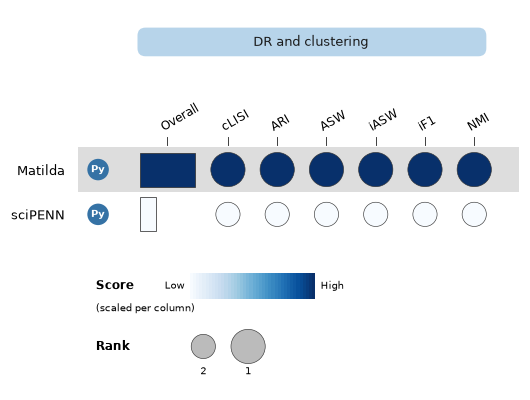

In [5]:
res.plot()

## 5. Your own data

Your data needs raw counts for both modalities and a cell type for each cell, in one `.h5ad` file. ADT means the protein counts.

Several donors or samples in the file? Keep them in one folder, without `batch=` in `export_dataset`, and give `run_all` the column itself: `mtb.run_all(..., batch=adata.obs["donor"])`. The summary then has the scores for how well they mix.

Starting from something else? See the recipes for [a 10x `.h5` file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-10x-h5), [labels in a CSV file](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-labels-csv), [no labels](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-no-labels) and [several donors or samples](https://dsichang.github.io/scMultiBench/tutorials/run/#recipe-donors).

<details>
<summary>Details: export</summary>

The names in quotes say where your file holds each part. `"X"` is the main matrix, `"obsm:protein"` the matrix `obsm["protein"]`, `"layer:counts"` the layer `layers["counts"]`, and `"obs:celltype"` the column `obs["celltype"]`, which `"celltype"` alone names too. A wrong name after `obsm:`, `layer:` or `obs:` raises an error that lists the names the file has.

The example keeps the protein names in `adata.uns["protein_names"]`. A DataFrame in `adata.obsm["protein"]` brings its own names in its columns.

The donors that `run_all` gets as `batch=` are matched to the cells by barcode, and every cell needs a donor. A column name alone is not enough there, because `run_all` reads the folder and the folder holds no `obs` columns.

`NAME` is the dataset name for `scan` and `run_all`, and `mydata` is the folder that holds it (`data_path`). With a new value of `NAME`, the folder holds the files of your data only.

The check lists the methods you name. Without `methods=`, it lists every method that reads the modalities in the folder. Without `per_method=True`, it has one row per method variant and every column, such as the command of each method.

`export_dataset` raises `FileExistsError` when the folder holds files of other cells that the call does not write. `overwrite=True` does not remove them. Give `NAME` a new value.

`overwrite=True` replaces the files of an earlier run of this cell. Without it, `export_dataset` raises `FileExistsError` rather than replace a file.

</details>

The cells below read your data, write it as a dataset folder, check the folder and run the same methods on it. So that the notebook runs as it is, the next cell writes a small example file, `my_file.h5ad`, from 60% of the cells of `D11`. It leaves a file of your own with that name as it is.

In [6]:
mtb.data.write_example("D11")

wrote my_file.h5ad: 1,718 cells. RNA counts in X, protein counts in obsm["protein"], cell types in obs["celltype"].


Read your file. For your own data, change the file name marked `# <-`. On Colab, upload the file first: click the folder icon on the left, then the upload icon. The cell reads `.h5ad` files. A 10x `.h5` file is read another way: see the recipe for a 10x `.h5` file, linked at the top of this section.

In [7]:
import anndata as ad

adata = ad.read_h5ad("my_file.h5ad")   # <- your file
adata

AnnData object with n_obs × n_vars = 1718 × 9822
    obs: 'celltype'
    uns: 'protein_names'
    obsm: 'protein'

Write the dataset folder. Change each name in quotes marked `# <-`: give `NAME` a new value, and write the names that your file uses for the other parts. The printout above lists the names in your file. Write a name listed after `obs:` with that prefix, as `"obs:celltype"`, and one after `obsm:` as `"obsm:protein"`.

In [8]:
NAME = "MYCITE"   # <- a new name for your own data
mtb.io.export_dataset(adata, "mydata/" + NAME,
                      rna="X",                # <- where the RNA counts are
                      adt="obsm:protein",     # <- where the proteins (ADT) are
                      labels="obs:celltype",  # <- the cell-type column
                      overwrite=True)

PosixPath('mydata/MYCITE')

Check the folder before you run anything. `runnable` says whether a method can run on your data on this computer, and `reason` says why not. The first two lines above the table say what the folder holds and how many cells each file has. Compare them with your data. A further line is about one method: why it cannot run, or what it does not read or needs from your data.

In [9]:
mtb.scan(NAME, "vertical", methods=METHODS, data_path="mydata",
         per_method=True)

[scan] 2 of 2 methods have their input files in MYCITE. 2 of 2 can run on this computer. MYCITE holds RNA and ADT.


[scan] Cells per file: rna.h5 1,718, adt.h5 1,718.


,method,runnable,reason
0,Matilda,True,
1,sciPENN,True,


Run the same methods on the folder:

In [10]:
mine = mtb.run_all(NAME, "vertical", methods=METHODS, data_path="mydata",
                   out_dir="out/" + NAME)
mine.summary

[run_all] Matilda (vertical/MYCITE) ...


[run_all]   -> CHAIN_OK (8.6s) ARI 0.948


[run_all] sciPENN (vertical/MYCITE) ...


[run_all]   -> CHAIN_OK (7.1s) ARI 0.584


,method,status,run_sec,output_kind,emb_shape,n_tunable,label_order,label_order_confidence,batch_source,n_batches,ARI,NMI,ASW,iASW,iF1,cLISI,label_order_note,caveat,reason
0,Matilda,CHAIN_OK,8.6,embedding,"[1718, 100]",10,cty.csv,NaN,None,1,0.9475,0.9481,0.6726,0.6910,0.9809,0.9993,single ordering,,
1,sciPENN,CHAIN_OK,7.1,embedding,"[1718, 512]",1,cty.csv,NaN,None,1,0.5838,0.6917,0.6090,0.6178,0.6621,0.9653,single ordering,,


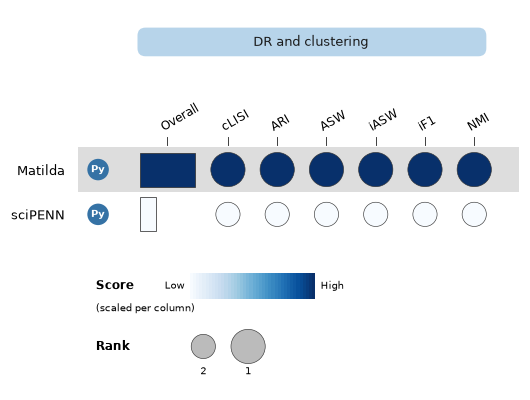

In [11]:
mine.plot()

## 6. Stored scores

The package ships stored scores for 13 methods on `D11`. `load_results` reads them and `mtb.plot.bubble` draws them, without running anything.

<details>
<summary>Details</summary>

`source="rerun"` reads the package's own runs of the methods. `source="published"`, the default, reads the published scIB tables, which hold 6 methods for `D11`.

The stored scores used the `leidenalg` backend for Leiden clustering, and `run_all` uses `igraph` by default. The two backends can move ARI by up to about 0.1. To compare your runs with these scores, set `mtb.config.DEFAULT.leiden_flavor = "leidenalg"` before `run_all`.

</details>

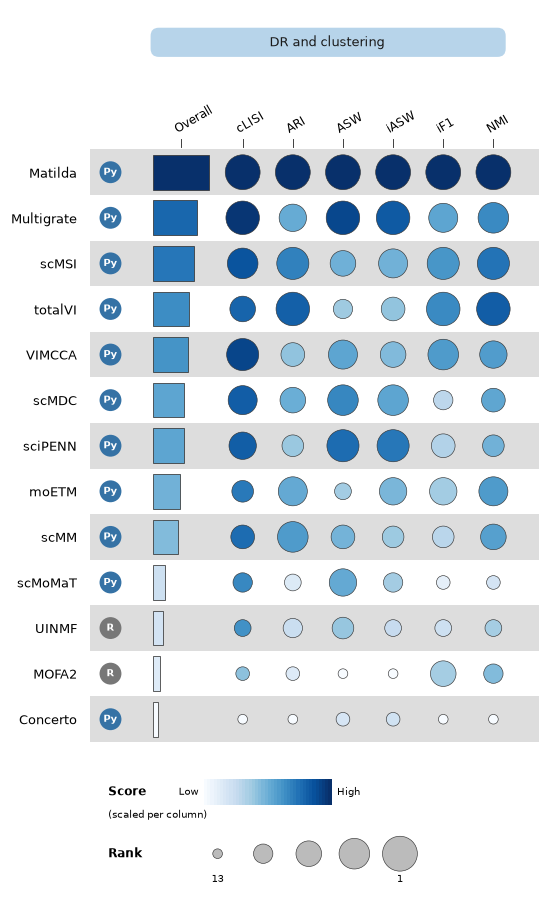

In [12]:
long = mtb.load_results("vertical", dataset="D11", source="rerun")
mtb.plot.bubble(long)

## 7. Every method of this task

14 methods have a variant for vertical RNA + ADT. Each ran on `D11` in the package's own check, on a server with a GPU:

| Method | Result | Seconds |
|---|---|---|
| Concerto | scored | 210 |
| MOFA2 | scored | 45 |
| Matilda | scored | 17 |
| Multigrate | scored | 42 |
| Seurat_WNN | ran, graph output not scored | 17 |
| UINMF | scored | 18 |
| VIMCCA | scored | 17 |
| moETM | scored | 9 |
| scMDC | scored | 70 |
| scMM | scored | 32 |
| scMSI | scored | 537 |
| scMoMaT | scored on the UMAP it writes | 59 |
| sciPENN | scored | 9 |
| totalVI | scored | 59 |

To run them all, set `METHODS` to these names in section 2 and run the notebook again. That downloads 14 envs, 32.5 GB to download on a CPU host, 40.8 GB on a GPU host. [This notebook](https://colab.research.google.com/github/DSichang/scMultiBench/blob/main/notebooks/tutorial_vertical_rna_adt_all.ipynb) does the same in Colab.

## Troubleshooting

`res.failures` lists each method that failed or was skipped. Its `error` column ends with the method's error output.

<details>
<summary>Details</summary>

| symptom | fix |
|---|---|
| `env.install` refuses on macOS or Windows | methods run only on Linux: use Colab or a Linux machine |
| a method needs an NVIDIA GPU | choose a GPU runtime on Colab, or a machine with a GPU |
| a method fails on a small dataset | `mtb.scan` without `per_method=True` names what the method needs from the data's size in its `caveat` column |
| a warning that values are not whole numbers | export raw counts, for example with `rna="layer:counts"` |
| `... matrix/data as cells x features` | the matrix is transposed: export it again with `mtb.io.export_dataset` |
| a method times out | raise `timeout=` in `run_all` |
| low `label_order_confidence` | several label files fit the cell count: check `label_order_candidates` in `res.results` |
| batch metrics use the wrong batches | `res.rescore(batch=my_vector)` scores again without running the methods |

</details>

## Next steps

- `mtb.cite(METHODS)` returns the citations for the benchmark and the methods you ran.
- The other tutorials: [vertical RNA + ATAC](https://dsichang.github.io/scMultiBench/tutorials/vertical_rna_atac/), [vertical RNA + ADT + ATAC](https://dsichang.github.io/scMultiBench/tutorials/vertical_rna_adt_atac/), [diagonal [RNA, ATAC]](https://dsichang.github.io/scMultiBench/tutorials/diagonal_rna_atac/), [diagonal [multiple RNA, multiple ATAC]](https://dsichang.github.io/scMultiBench/tutorials/diagonal_multi/), [mosaic [RNA, RNA + ADT, ADT]](https://dsichang.github.io/scMultiBench/tutorials/mosaic_rna_adt/), [mosaic [RNA, RNA + ATAC, ATAC]](https://dsichang.github.io/scMultiBench/tutorials/mosaic_rna_atac/), [mosaic Mixed, with shared modality](https://dsichang.github.io/scMultiBench/tutorials/mosaic_shared/), [mosaic Mixed, without shared modality](https://dsichang.github.io/scMultiBench/tutorials/mosaic_unshared/), [cross Multiple RNA + ADT](https://dsichang.github.io/scMultiBench/tutorials/cross_rna_adt/), [cross Multiple RNA + ATAC](https://dsichang.github.io/scMultiBench/tutorials/cross_rna_atac/), [cross Multiple ADT + ATAC](https://dsichang.github.io/scMultiBench/tutorials/cross_adt_atac/), [cross Multiple RNA + ADT + ATAC](https://dsichang.github.io/scMultiBench/tutorials/cross_rna_adt_atac/).
- The guides: [run](https://dsichang.github.io/scMultiBench/tutorials/run/), [evaluate](https://dsichang.github.io/scMultiBench/tutorials/evaluate/), [plot](https://dsichang.github.io/scMultiBench/tutorials/plot/) and [discover methods](https://dsichang.github.io/scMultiBench/tutorials/discover/).
- The [interactive explorer](https://shiny.maths.usyd.edu.au/scMultiBench/) has the full benchmark's rankings, with no install needed.